In [ ]:
# Retail Sales & Customer Segmentation Analysis
===============================================

## 1. Project Introduction
      ====================

### Business Problem
To analyze retail sales data, understand customer purchasing behavior,
identify valuable customer segments, and discover sales and product patterns.
;
### Project Objective
- Analyze overall retail sales performance
- Understand customer purchasing behavior
- Perform RFM analysis
- Segment customers based on their purchasing behavior
- Identify important product and country-level sales patterns
- Generate actionable business insights

In [ ]:
## 2. Dataset & Data Understanding
     ==============================

### Dataset
Online Retail Transaction Dataset

### Dataset Description
The dataset contains transaction-level records from an online retail business.

### Key Columns
- InvoiceNo – Invoice number
- StockCode – Product code
- Description – Product description
- Quantity – Number of items purchased
- InvoiceDate – Date and time of transaction
- UnitPrice – Price per item
- CustomerID – Unique customer identifier
- Country – Customers country

In [138]:
import pandas as pd

df = pd.read_excel(
    r"C:\Users\acer\Downloads\Online Retail.xlsx\Online Retail.xlsx"
)
print(df.shape)

(541909, 8)


In [139]:
print(df.head())

  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                  WHITE METAL LANTERN         6   
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

          InvoiceDate  UnitPrice  CustomerID         Country  
0 2010-12-01 08:26:00       2.55     17850.0  United Kingdom  
1 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
2 2010-12-01 08:26:00       2.75     17850.0  United Kingdom  
3 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
4 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  


In [140]:
print(df.columns)
print(df.info())

Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country'],
      dtype='object')
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB
None


In [ ]:
## 3. Data Cleaning & Preparation
     ============================

In [141]:
print(df.isnull().sum())

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


In [142]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 5268


In [143]:
df = df.drop_duplicates()

print("New shape:", df.shape)

New shape: (536641, 8)


In [144]:
print("Negative quantities:", (df["Quantity"] < 0).sum())
print("Zero quantities:", (df["Quantity"] == 0).sum())

Negative quantities: 10587
Zero quantities: 0


In [145]:
print(df[df["Quantity"] < 0][
    ["InvoiceNo", "Quantity", "UnitPrice", "CustomerID", "Description"]
].head(10))

    InvoiceNo  Quantity  UnitPrice  CustomerID  \
141   C536379        -1      27.50     14527.0   
154   C536383        -1       4.65     15311.0   
235   C536391       -12       1.65     17548.0   
236   C536391       -24       0.29     17548.0   
237   C536391       -24       0.29     17548.0   
238   C536391       -24       0.29     17548.0   
239   C536391       -12       3.45     17548.0   
240   C536391       -12       1.65     17548.0   
241   C536391       -24       1.65     17548.0   
939   C536506        -6       4.25     17897.0   

                           Description  
141                           Discount  
154    SET OF 3 COLOURED  FLYING DUCKS  
235     PLASTERS IN TIN CIRCUS PARADE   
236   PACK OF 12 PINK PAISLEY TISSUES   
237   PACK OF 12 BLUE PAISLEY TISSUES   
238  PACK OF 12 RED RETROSPOT TISSUES   
239        CHICK GREY HOT WATER BOTTLE  
240   PLASTERS IN TIN VINTAGE PAISLEY   
241             PLASTERS IN TIN SKULLS  
939           JAM MAKING SET WITH JARS 

In [146]:
print("Cancelled invoices:", df["InvoiceNo"].astype(str).str.startswith("C").sum())

Cancelled invoices: 9251


In [147]:
sales_df = df[~df["InvoiceNo"].astype(str).str.startswith("C")].copy()

print("Original rows:", len(df))
print("Purchase rows:", len(sales_df))

Original rows: 536641
Purchase rows: 527390


In [148]:
print("Zero prices:", (sales_df["UnitPrice"] == 0).sum())
print("Negative prices:", (sales_df["UnitPrice"] < 0).sum())

Zero prices: 2510
Negative prices: 2


In [149]:
sales_df = sales_df[sales_df["UnitPrice"] > 0].copy()

print("Rows after price cleaning:", len(sales_df))

Rows after price cleaning: 524878


In [150]:
print("Missing CustomerID:", sales_df["CustomerID"].isnull().sum())
print("Valid CustomerID:", sales_df["CustomerID"].notnull().sum())

Missing CustomerID: 132186
Valid CustomerID: 392692


In [151]:
print("Earliest date:", sales_df["InvoiceDate"].min())
print("Latest date:", sales_df["InvoiceDate"].max())

Earliest date: 2010-12-01 08:26:00
Latest date: 2011-12-09 12:50:00


In [ ]:
## 4. Exploratory Data Analysis (EDA)
     ================================

In [152]:
sales_df["TotalAmount"] = sales_df["Quantity"] * sales_df["UnitPrice"]

print(sales_df[["Quantity", "UnitPrice", "TotalAmount"]].head())

   Quantity  UnitPrice  TotalAmount
0         6       2.55        15.30
1         6       3.39        20.34
2         8       2.75        22.00
3         6       3.39        20.34
4         6       3.39        20.34


In [153]:
monthly_sales = (
    sales_df.set_index("InvoiceDate")
    .resample("ME")["TotalAmount"]
    .sum()
)

print(monthly_sales)

InvoiceDate
2010-12-31     821452.730
2011-01-31     689811.610
2011-02-28     522545.560
2011-03-31     716215.260
2011-04-30     536968.491
2011-05-31     769296.610
2011-06-30     760547.010
2011-07-31     718076.121
2011-08-31     757841.380
2011-09-30    1056435.192
2011-10-31    1151263.730
2011-11-30    1503866.780
2011-12-31     637790.330
Freq: ME, Name: TotalAmount, dtype: float64


In [154]:
import matplotlib.pyplot as plt

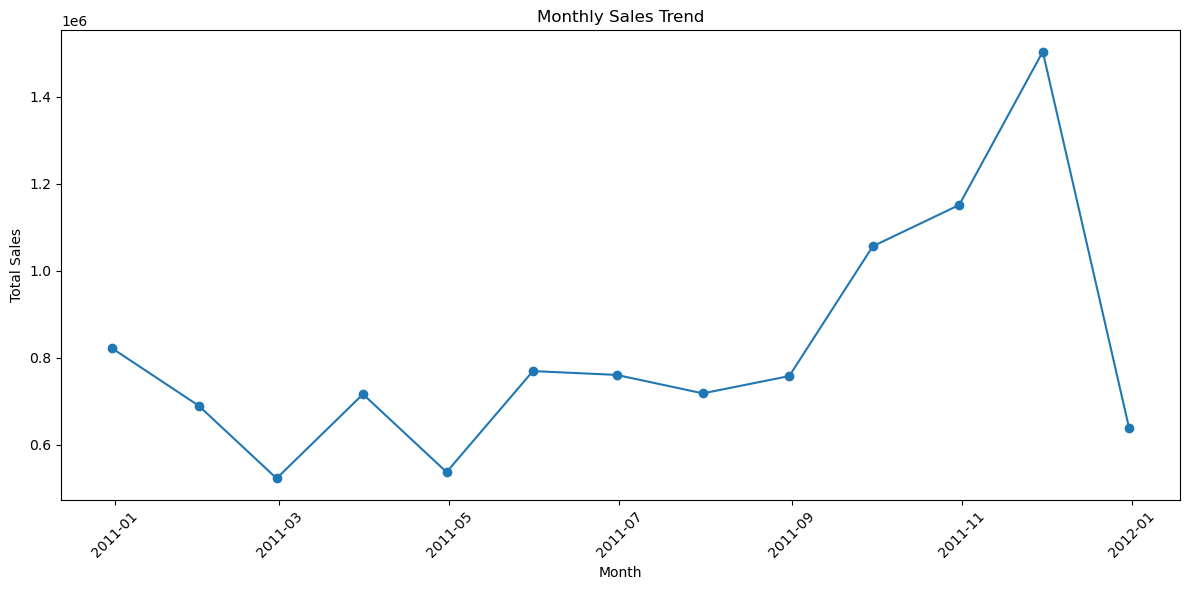

In [155]:
plt.figure(figsize=(12, 6))

plt.plot(
    monthly_sales.index,
    monthly_sales.values,
    marker="o"
)

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [156]:
monthly_orders = (
    sales_df.set_index("InvoiceDate")
    .resample("ME")["InvoiceNo"]
    .nunique()
)

print(monthly_orders)

InvoiceDate
2010-12-31    1559
2011-01-31    1086
2011-02-28    1100
2011-03-31    1454
2011-04-30    1246
2011-05-31    1681
2011-06-30    1533
2011-07-31    1475
2011-08-31    1361
2011-09-30    1837
2011-10-31    2040
2011-11-30    2769
2011-12-31     819
Freq: ME, Name: InvoiceNo, dtype: int64


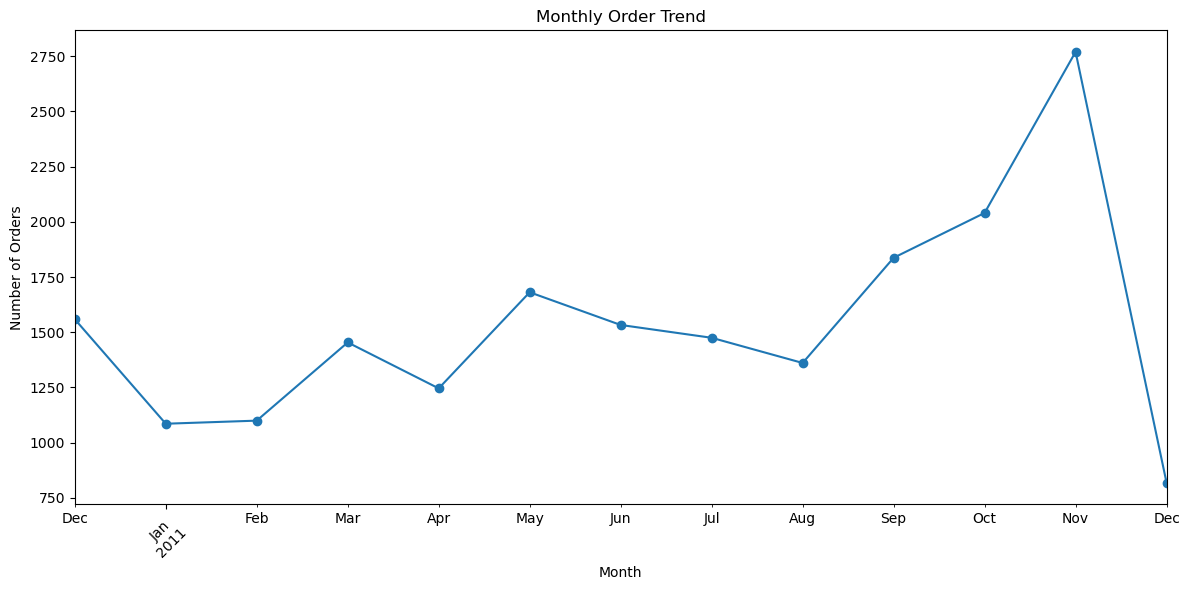

In [157]:
plt.figure(figsize=(12, 6))

monthly_orders.plot(kind="line", marker="o")

plt.title("Monthly Order Trend")
plt.xlabel("Month")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [158]:
average_order_value = monthly_sales / monthly_orders

print(average_order_value)


InvoiceDate
2010-12-31    526.910026
2011-01-31    635.185645
2011-02-28    475.041418
2011-03-31    492.582710
2011-04-30    430.953845
2011-05-31    457.642243
2011-06-30    496.116771
2011-07-31    486.831268
2011-08-31    556.826877
2011-09-30    575.087203
2011-10-31    564.344966
2011-11-30    543.108263
2011-12-31    778.742772
Freq: ME, dtype: float64


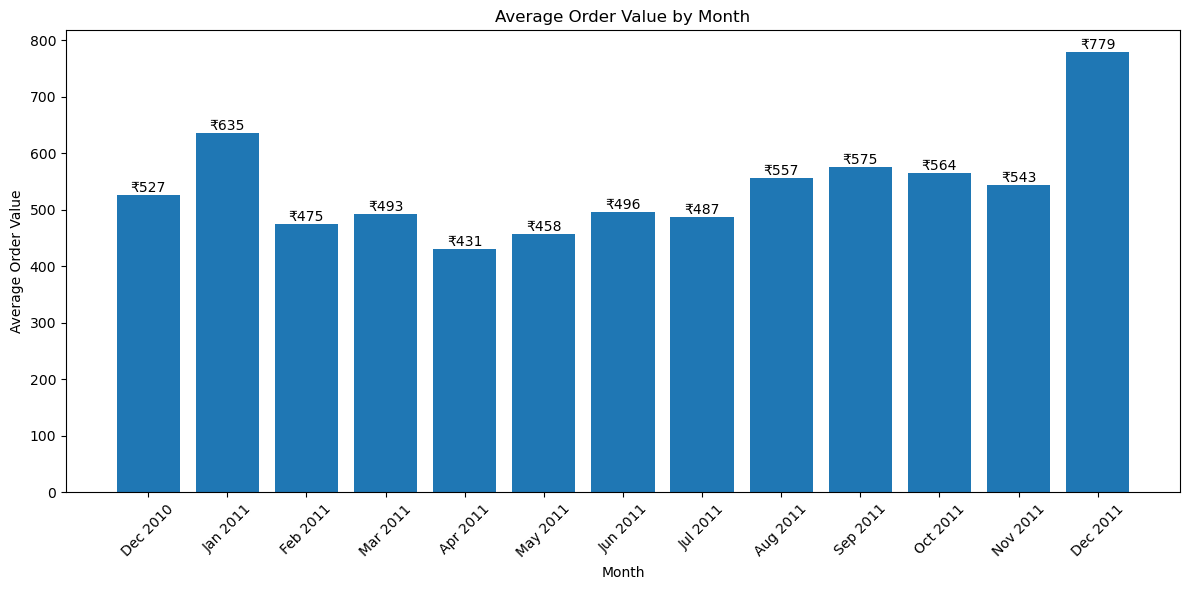

In [159]:
plt.figure(figsize=(12, 6))

aov = average_order_value.copy()
aov.index = aov.index.strftime("%b %Y")

bars = plt.bar(aov.index, aov.values)

plt.title("Average Order Value by Month")
plt.xlabel("Month")
plt.ylabel("Average Order Value")
plt.xticks(rotation=45)

# Display values on top of bars
for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"₹{bar.get_height():.0f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

In [160]:
day_sales = (
    sales_df.assign(
        DayOfWeek=sales_df["InvoiceDate"].dt.day_name()
    )
    .groupby("DayOfWeek")["TotalAmount"]
    .sum()
)

print(day_sales)

DayOfWeek
Friday       1837470.491
Monday       1775782.071
Sunday        806790.781
Thursday     2199292.570
Tuesday      2175700.511
Wednesday    1847074.380
Name: TotalAmount, dtype: float64


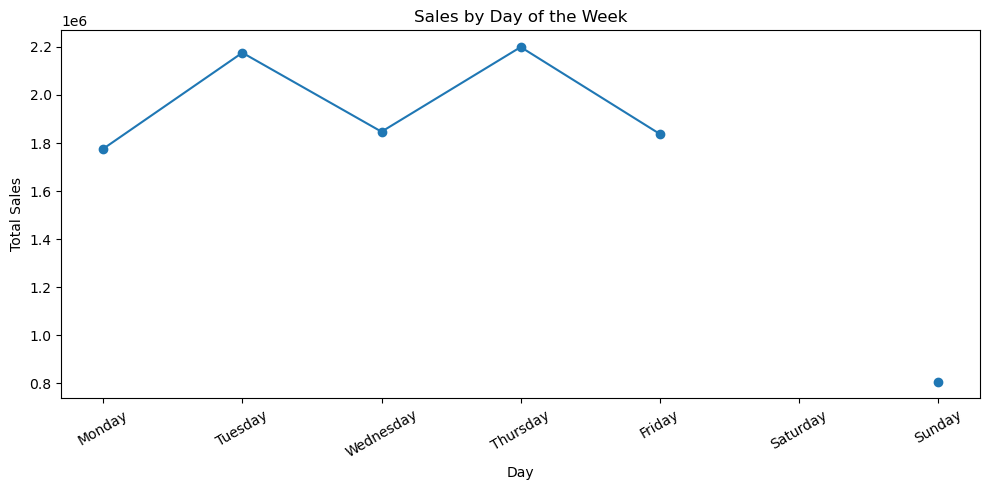

In [161]:
day_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

day_sales = day_sales.reindex(day_order)

plt.figure(figsize=(10, 5))
plt.plot(day_sales.index, day_sales.values, marker="o")
plt.title("Sales by Day of the Week")
plt.xlabel("Day")
plt.ylabel("Total Sales")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

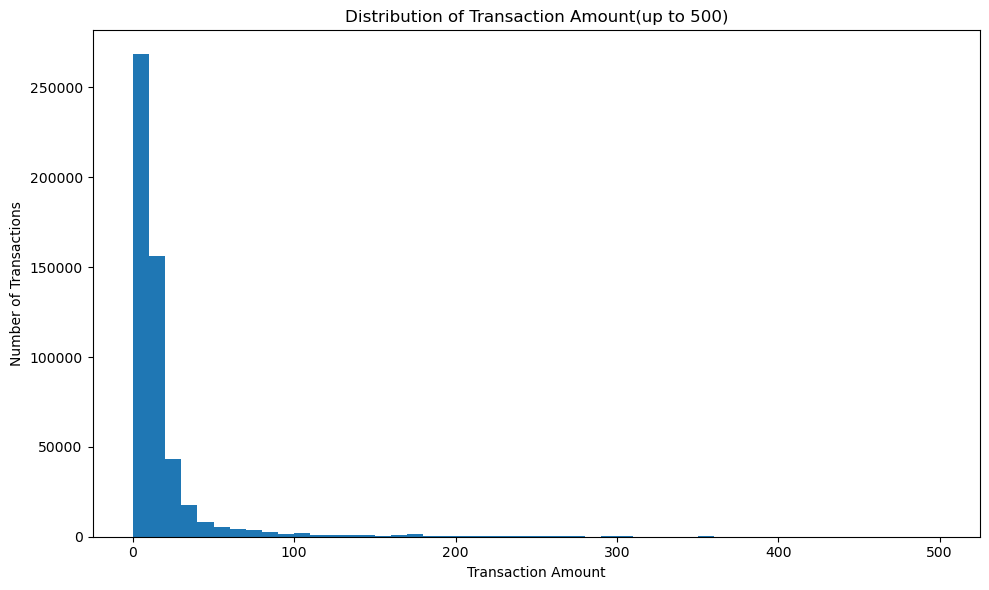

In [162]:
plt.figure(figsize=(10, 6))
plt.hist(
    sales_df[sales_df["TotalAmount"]<=500]["TotalAmount"],
    bins=50
)
plt.title("Distribution of Transaction Amount(up to 500)")
plt.xlabel("Transaction Amount")
plt.ylabel("Number of Transactions")
plt.tight_layout()
plt.show()

In [163]:
country_sales = (
    sales_df.groupby("Country")["TotalAmount"]
    .sum()
    .sort_values(ascending=False)
)

print(country_sales.head(10))

Country
United Kingdom    9001744.094
Netherlands        285446.340
EIRE               283140.520
Germany            228678.400
France             209625.370
Australia          138453.810
Spain               61558.560
Switzerland         57067.600
Belgium             41196.340
Sweden              38367.830
Name: TotalAmount, dtype: float64


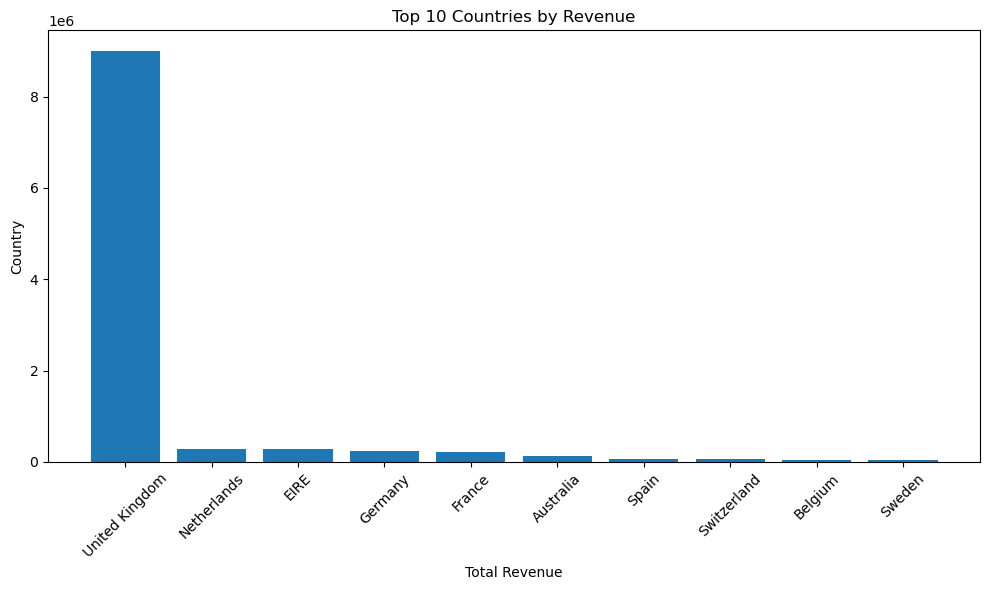

In [164]:
plt.figure(figsize=(10, 6))

plt.bar(country_sales.head(10).index,
        country_sales.head(10).values)

plt.title("Top 10 Countries by Revenue")
plt.xlabel("Total Revenue")
plt.ylabel("Country")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [ ]:
## 5. RFM Customer Analysis
     ======================

In [ ]:
### RFM Analysis

RFM analysis is used to understand customer purchasing behavior based on three factors:

- Recency – How recently a customer made a purchase
- Frequency – How often a customer made a purchase
- Monetary – How much a customer spent

In [165]:
rfm_df = sales_df[sales_df["CustomerID"].notnull()].copy()

print("RFM dataset shape:", rfm_df.shape)
print("Unique customers:", rfm_df["CustomerID"].nunique())

RFM dataset shape: (392692, 9)
Unique customers: 4338


In [166]:
rfm_df["TotalAmount"] = rfm_df["Quantity"] * rfm_df["UnitPrice"]

print(rfm_df[["Quantity", "UnitPrice", "TotalAmount"]].head())

   Quantity  UnitPrice  TotalAmount
0         6       2.55        15.30
1         6       3.39        20.34
2         8       2.75        22.00
3         6       3.39        20.34
4         6       3.39        20.34


In [167]:
reference_date = rfm_df["InvoiceDate"].max()

recency_df = rfm_df.groupby("CustomerID")["InvoiceDate"].max().reset_index()

recency_df["Recency"] = (
    reference_date - recency_df["InvoiceDate"]
).dt.days

print(recency_df.head())


   CustomerID         InvoiceDate  Recency
0     12346.0 2011-01-18 10:01:00      325
1     12347.0 2011-12-07 15:52:00        1
2     12348.0 2011-09-25 13:13:00       74
3     12349.0 2011-11-21 09:51:00       18
4     12350.0 2011-02-02 16:01:00      309


In [168]:
frequency_df = (
    rfm_df.groupby("CustomerID")["InvoiceNo"]
    .nunique()
    .reset_index()
)

frequency_df.columns = ["CustomerID", "Frequency"]

print(frequency_df.head())

   CustomerID  Frequency
0     12346.0          1
1     12347.0          7
2     12348.0          4
3     12349.0          1
4     12350.0          1


In [169]:
monetary_df = (
    rfm_df.groupby("CustomerID")["TotalAmount"]
    .sum()
    .reset_index()
)

monetary_df.columns = ["CustomerID", "Monetary"]

print(monetary_df.head())

   CustomerID  Monetary
0     12346.0  77183.60
1     12347.0   4310.00
2     12348.0   1797.24
3     12349.0   1757.55
4     12350.0    334.40


In [170]:
rfm = recency_df[["CustomerID", "Recency"]].merge(
    frequency_df,
    on="CustomerID"
).merge(
    monetary_df,
    on="CustomerID"
)

print(rfm.head())
print("\nShape:", rfm.shape)

   CustomerID  Recency  Frequency  Monetary
0     12346.0      325          1  77183.60
1     12347.0        1          7   4310.00
2     12348.0       74          4   1797.24
3     12349.0       18          1   1757.55
4     12350.0      309          1    334.40

Shape: (4338, 4)


In [171]:
print(rfm[["Recency", "Frequency", "Monetary"]].describe())

           Recency    Frequency       Monetary
count  4338.000000  4338.000000    4338.000000
mean     91.536422     4.272015    2048.688081
std     100.014169     7.697998    8985.230220
min       0.000000     1.000000       3.750000
25%      17.000000     1.000000     306.482500
50%      50.000000     2.000000     668.570000
75%     141.000000     5.000000    1660.597500
max     373.000000   209.000000  280206.020000


In [172]:
rfm["R_Score"] = pd.qcut(
    rfm["Recency"],
    5,
    labels=[5, 4, 3, 2, 1]
)

rfm["F_Score"] = pd.qcut(
    rfm["Frequency"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
)

rfm["M_Score"] = pd.qcut(
    rfm["Monetary"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
)

print(rfm.head())

   CustomerID  Recency  Frequency  Monetary R_Score F_Score M_Score
0     12346.0      325          1  77183.60       1       1       5
1     12347.0        1          7   4310.00       5       5       5
2     12348.0       74          4   1797.24       2       4       4
3     12349.0       18          1   1757.55       4       1       4
4     12350.0      309          1    334.40       1       1       2


In [173]:
rfm["RFM_Score"] = (
    rfm["R_Score"].astype(str)
    + rfm["F_Score"].astype(str)
    + rfm["M_Score"].astype(str)
)

print(rfm.head())

   CustomerID  Recency  Frequency  Monetary R_Score F_Score M_Score RFM_Score
0     12346.0      325          1  77183.60       1       1       5       115
1     12347.0        1          7   4310.00       5       5       5       555
2     12348.0       74          4   1797.24       2       4       4       244
3     12349.0       18          1   1757.55       4       1       4       414
4     12350.0      309          1    334.40       1       1       2       112


In [137]:
## 6. Customer Segmentation
      =====================

In [174]:
def segment_customer(row):
    if row["R_Score"] >= 4 and row["F_Score"] >= 4 and row["M_Score"] >= 4:
        return "Champions"
    elif row["R_Score"] >= 4 and row["F_Score"] >= 3:
        return "Loyal Customers"
    elif row["R_Score"] >= 4 and row["F_Score"] <= 2:
        return "New Customers"
    elif row["R_Score"] <= 2 and row["F_Score"] >= 3:
        return "At Risk"
    elif row["R_Score"] <= 2 and row["F_Score"] <= 2:
        return "Lost Customers"
    else:
        return "Potential Loyalists"

rfm["Segment"] = rfm.apply(segment_customer, axis=1)

print(rfm[[
    "CustomerID",
    "Recency",
    "Frequency",
    "Monetary",
    "RFM_Score",
    "Segment"
]].head(10))


   CustomerID  Recency  Frequency  Monetary RFM_Score              Segment
0     12346.0      325          1  77183.60       115       Lost Customers
1     12347.0        1          7   4310.00       555            Champions
2     12348.0       74          4   1797.24       244              At Risk
3     12349.0       18          1   1757.55       414        New Customers
4     12350.0      309          1    334.40       112       Lost Customers
5     12352.0       35          8   2506.04       355  Potential Loyalists
6     12353.0      203          1     89.00       111       Lost Customers
7     12354.0      231          1   1079.40       114       Lost Customers
8     12355.0      213          1    459.40       112       Lost Customers
9     12356.0       22          3   2811.43       435      Loyal Customers


In [175]:
segment_counts = rfm["Segment"].value_counts()

print(segment_counts)

Segment
Lost Customers         1065
Champions               957
Potential Loyalists     858
At Risk                 643
Loyal Customers         496
New Customers           319
Name: count, dtype: int64


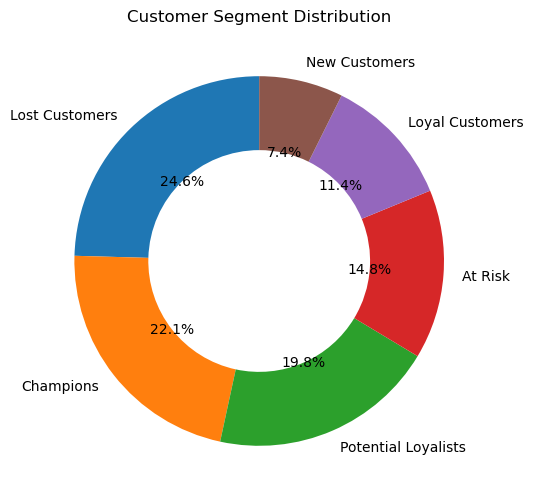

In [176]:
plt.figure(figsize=(6, 6))

plt.pie(
    segment_counts,
    labels=segment_counts.index,
    autopct="%1.1f%%",
    startangle=90,
    wedgeprops={"width": 0.4}
)

plt.title("Customer Segment Distribution")
plt.show()

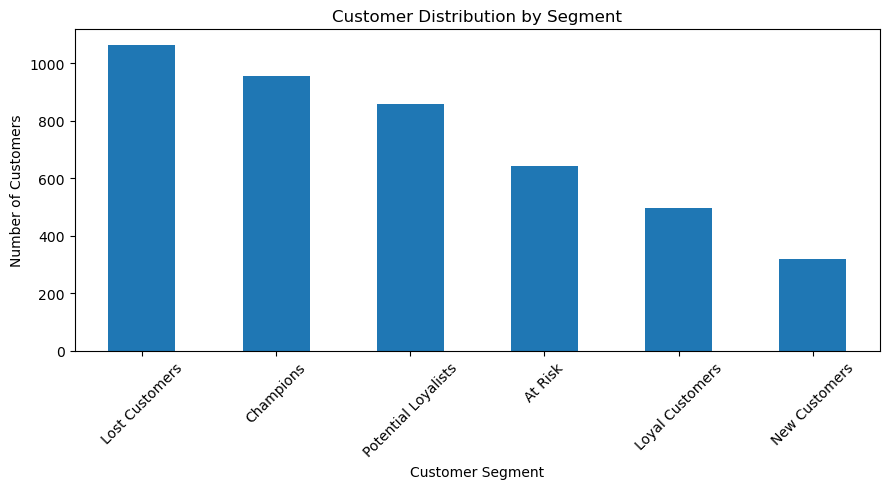

In [177]:
import matplotlib.pyplot as plt

segment_counts = rfm["Segment"].value_counts()

plt.figure(figsize=(9, 5))

segment_counts.plot(kind="bar")

plt.title("Customer Distribution by Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [178]:
segment_revenue = (
    rfm.groupby("Segment")["Monetary"]
    .sum()
    .sort_values(ascending=False)
)
print(segment_revenue)

Segment
Champions              5791640.740
Potential Loyalists    1099446.880
At Risk                 798052.511
Loyal Customers         534526.871
Lost Customers          518322.152
New Customers           145219.740
Name: Monetary, dtype: float64


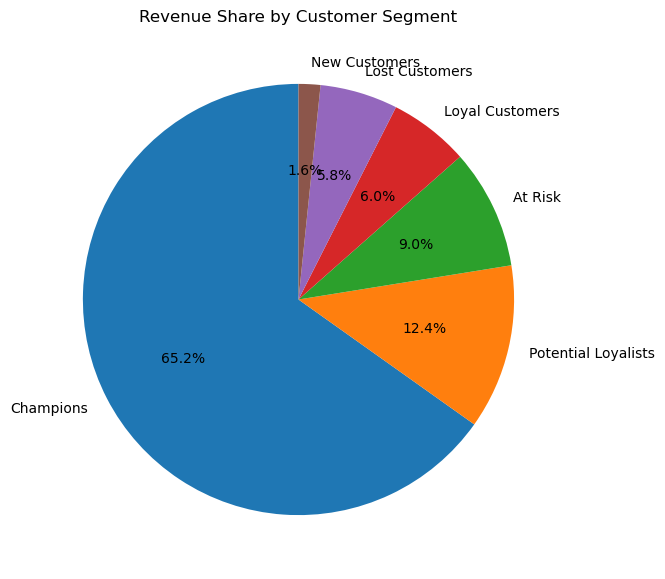

In [179]:
plt.figure(figsize=(7, 7))

segment_revenue.plot(
    kind="pie",
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Revenue Share by Customer Segment")
plt.ylabel("")

plt.show()

In [180]:
avg_spending = (
    rfm.groupby("Segment")["Monetary"]
    .mean()
    .sort_values(ascending=False)
)
print(avg_spending)

Segment
Champions              6051.871202
Potential Loyalists    1281.406620
At Risk                1241.139208
Loyal Customers        1077.675143
Lost Customers          486.687467
New Customers           455.234295
Name: Monetary, dtype: float64


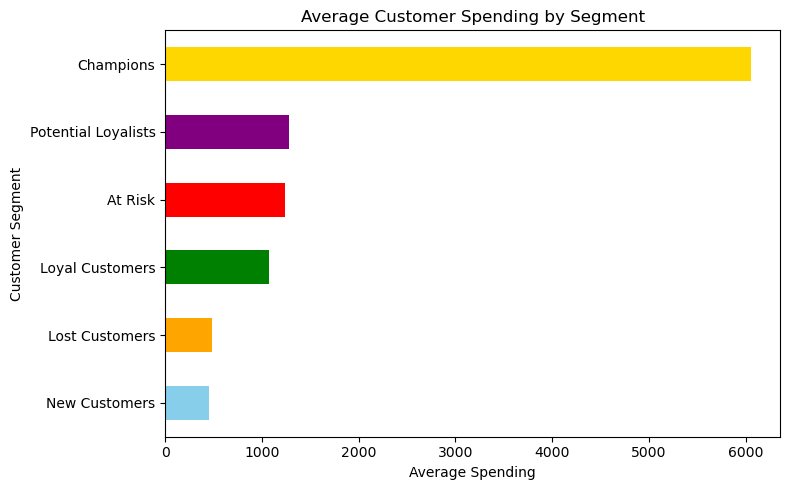

In [181]:
plt.figure(figsize=(8, 5))

avg_spending.sort_values().plot(
    kind="barh",
    color=["skyblue", "orange", "green", "red", "purple", "gold"]
)

plt.title("Average Customer Spending by Segment")
plt.xlabel("Average Spending")
plt.ylabel("Customer Segment")

plt.tight_layout()
plt.show()

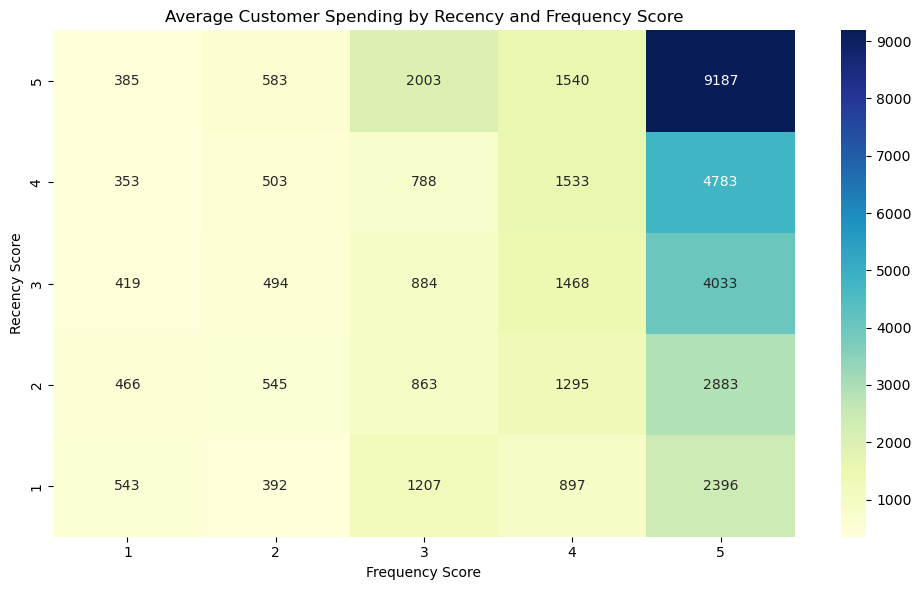

In [182]:
import seaborn as sns
import matplotlib.pyplot as plt

rfm_heatmap = rfm.pivot_table(
    values="Monetary",
    index="R_Score",
    columns="F_Score",
    aggfunc="mean",
    observed=False
)

plt.figure(figsize=(10, 6))

sns.heatmap(
    rfm_heatmap,
    annot=True,
    fmt=".0f",
    cmap="YlGnBu"
)

plt.title("Average Customer Spending by Recency and Frequency Score")
plt.xlabel("Frequency Score")
plt.ylabel("Recency Score")

plt.tight_layout()
plt.show()

In [183]:
rfm_correlation = rfm[
    ["Recency", "Frequency", "Monetary"]
].corr()

print(rfm_correlation)

            Recency  Frequency  Monetary
Recency    1.000000  -0.260578 -0.121831
Frequency -0.260578   1.000000  0.552780
Monetary  -0.121831   0.552780  1.000000


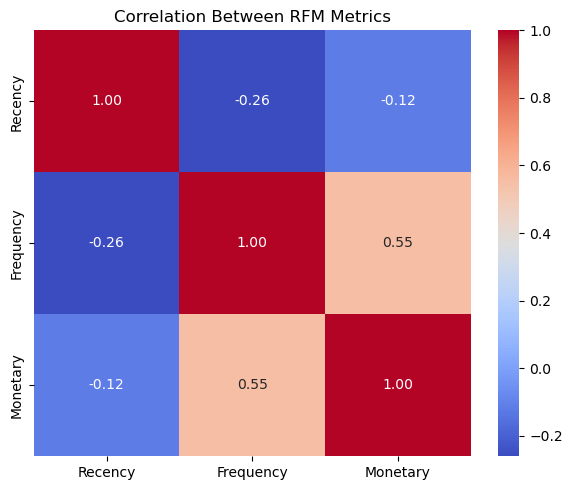

In [184]:
plt.figure(figsize=(6, 5))

sns.heatmap(
    rfm_correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Correlation Between RFM Metrics")
plt.tight_layout()
plt.show()

In [ ]:
## 7. Customer & Business Analysis
      ============================

In [185]:
top_customers = (
    rfm[["CustomerID", "Monetary"]]
    .sort_values("Monetary", ascending=False)
    .head(10)
)

print(top_customers)

      CustomerID   Monetary
1689     14646.0  280206.02
4201     18102.0  259657.30
3728     17450.0  194390.79
3008     16446.0  168472.50
1879     14911.0  143711.17
55       12415.0  124914.53
1333     14156.0  117210.08
3771     17511.0   91062.38
2702     16029.0   80850.84
0        12346.0   77183.60


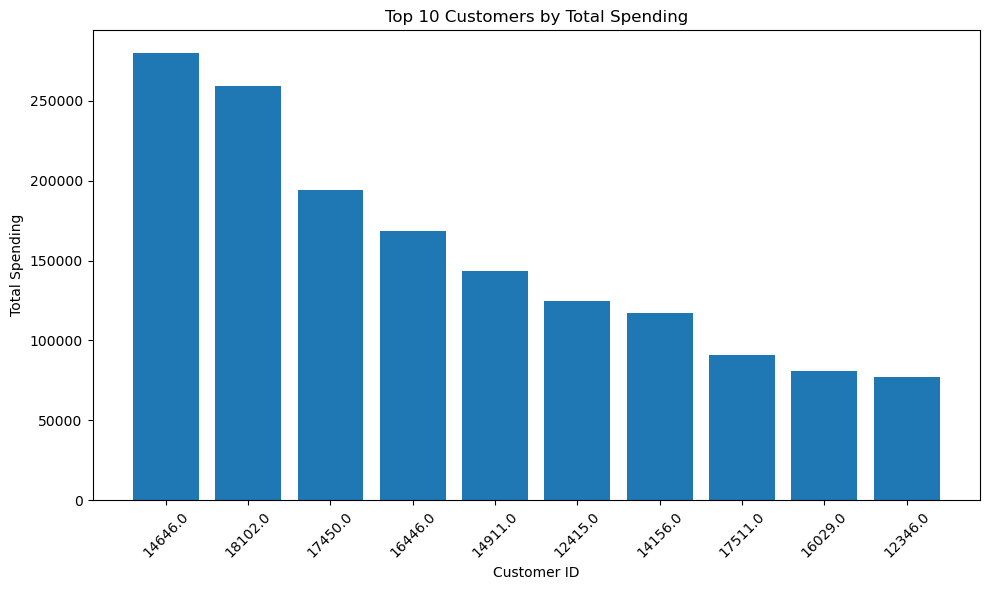

In [186]:
plt.figure(figsize=(10, 6))

plt.bar(
    top_customers["CustomerID"].astype(str),
    top_customers["Monetary"]
)

plt.title("Top 10 Customers by Total Spending")
plt.xlabel("Customer ID")
plt.ylabel("Total Spending")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [187]:
customer_orders = (
    rfm_df.groupby(["CustomerID", "InvoiceNo"])["TotalAmount"]
    .sum()
    .reset_index()
)

customer_orders = customer_orders.merge(
    rfm[["CustomerID", "Segment"]],
    on="CustomerID"
)

segment_aov = (
    customer_orders.groupby("Segment")["TotalAmount"]
    .mean()
    .sort_values(ascending=False)
)

print(segment_aov)

Segment
Champions              544.071465
Lost Customers         441.877367
Potential Loyalists    412.550424
New Customers          366.716515
Loyal Customers        365.113983
At Risk                364.574011
Name: TotalAmount, dtype: float64


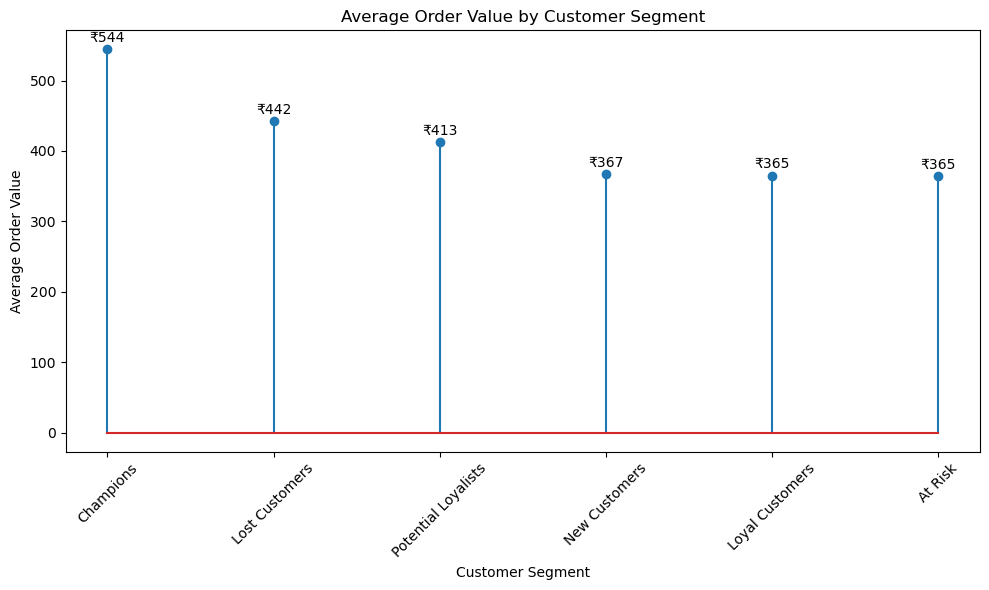

In [188]:
plt.figure(figsize=(10, 6))

segments = segment_aov.index
values = segment_aov.values

plt.stem(segments, values)

plt.title("Average Order Value by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Average Order Value")

plt.xticks(rotation=45)

for i, value in enumerate(values):
    plt.text(
        i,
        value + 10,
        f"₹{value:.0f}",
        ha="center"
    )

plt.tight_layout()
plt.show()

In [ ]:
### Business Interpretation of Customer Segments

- Champions: High-value customers who purchase recently and frequently. Focus on retention and loyalty.
- Loyal Customers: Customers with consistent purchasing behaviour. Encourage repeat purchases.
- New Customers: Recent customers with limited purchase history. Focus on converting them into repeat
  customers.
- Potential Loyalists: Customers showing potential for stronger engagement. Use targeted
  offers to encourage repeat purchases.
- At Risk: Previously engaged customers who have not purchased recently. Use re-engagement campaigns.
- Lost Customers: Customers with low recent activity. Consider win-back campaigns where appropriate.

In [ ]:
## 8. Product & Market Analysis
      =========================

In [189]:
product_sales = sales_df[
    ~sales_df["Description"].isin([
        "DOTCOM POSTAGE",
        "POSTAGE",
        "Manual"
    ])
].copy()

print("Original rows:", len(sales_df))
print("Product rows:", len(product_sales))

Original rows: 524878
Product rows: 522729


In [190]:
top_products = (
    sales_df.groupby("Description")["Quantity"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print(top_products)

Description
PAPER CRAFT , LITTLE BIRDIE           80995
MEDIUM CERAMIC TOP STORAGE JAR        78033
WORLD WAR 2 GLIDERS ASSTD DESIGNS     54951
JUMBO BAG RED RETROSPOT               48371
WHITE HANGING HEART T-LIGHT HOLDER    37872
POPCORN HOLDER                        36749
PACK OF 72 RETROSPOT CAKE CASES       36396
ASSORTED COLOUR BIRD ORNAMENT         36362
RABBIT NIGHT LIGHT                    30739
MINI PAINT SET VINTAGE                26633
Name: Quantity, dtype: int64


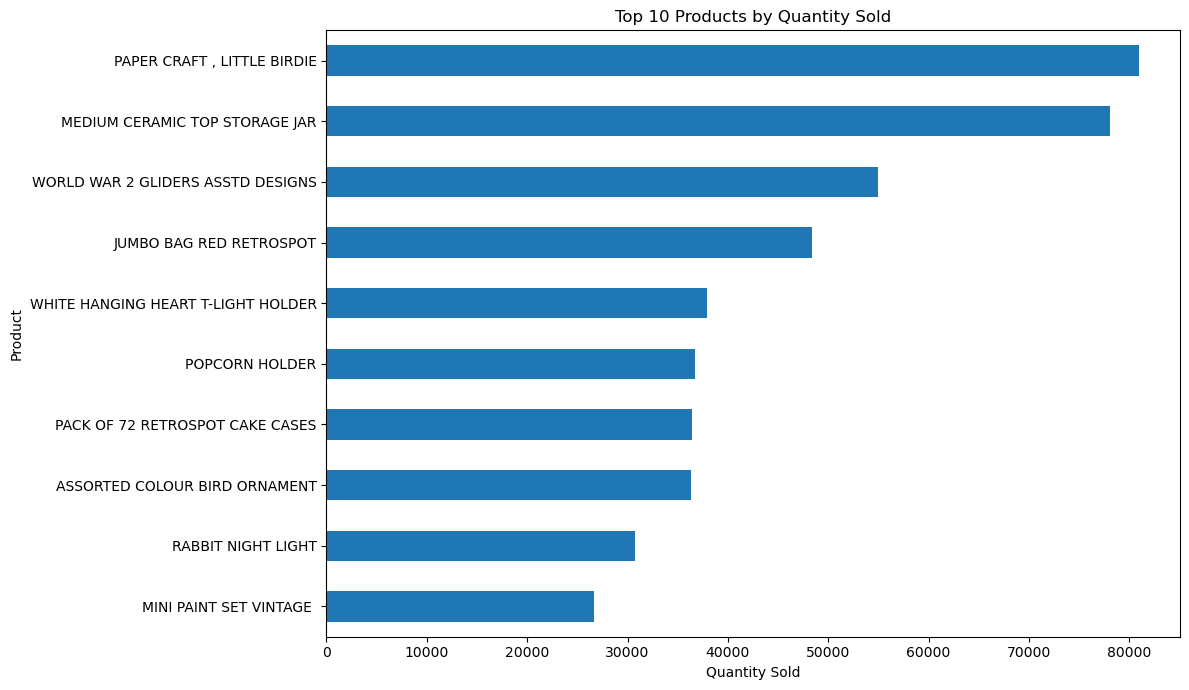

In [191]:
plt.figure(figsize=(12, 7))

top_products.sort_values().plot(
    kind="barh"
)

plt.title("Top 10 Products by Quantity Sold")
plt.xlabel("Quantity Sold")
plt.ylabel("Product")

plt.tight_layout()
plt.show()

In [192]:
top_revenue_products = (
    product_sales.groupby("Description")["TotalAmount"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print(top_revenue_products)

Description
REGENCY CAKESTAND 3 TIER              174156.54
PAPER CRAFT , LITTLE BIRDIE           168469.60
WHITE HANGING HEART T-LIGHT HOLDER    106236.72
PARTY BUNTING                          99445.23
JUMBO BAG RED RETROSPOT                94159.81
MEDIUM CERAMIC TOP STORAGE JAR         81700.92
RABBIT NIGHT LIGHT                     66870.03
PAPER CHAIN KIT 50'S CHRISTMAS         64875.59
ASSORTED COLOUR BIRD ORNAMENT          58927.62
CHILLI LIGHTS                          54096.36
Name: TotalAmount, dtype: float64


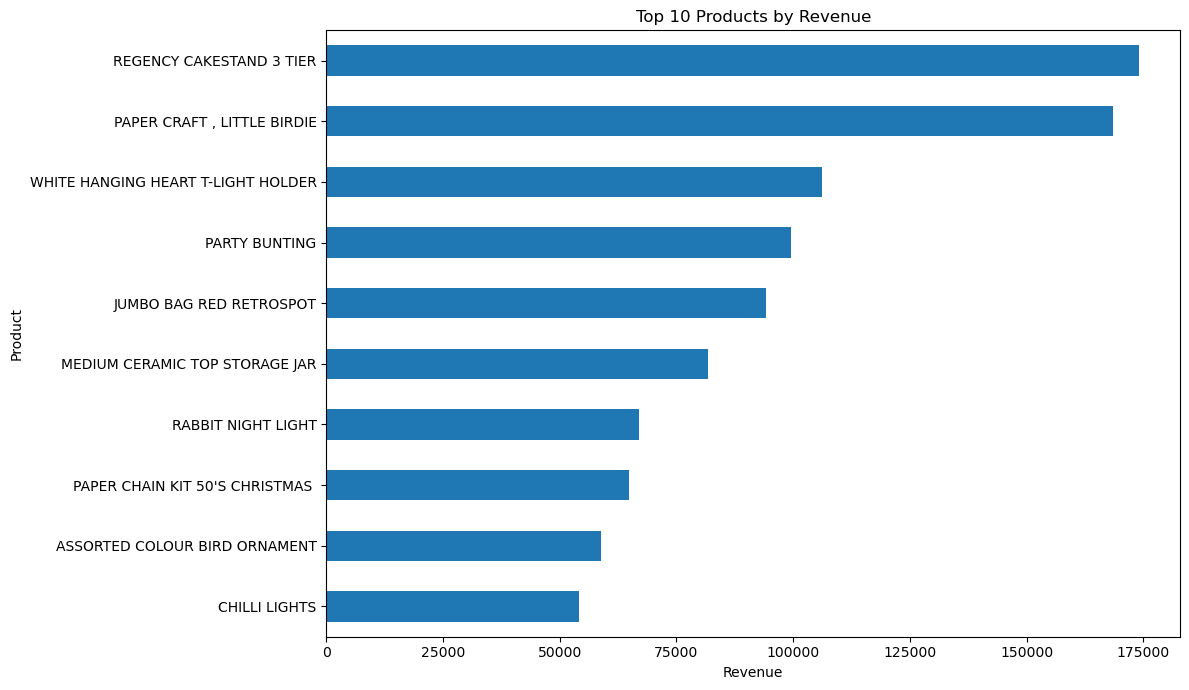

In [193]:
plt.figure(figsize=(12, 7))
top_revenue_products.sort_values().plot(kind="barh")
plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue")
plt.ylabel("Product")
plt.tight_layout()
plt.show()


In [194]:
product_performance = (
    product_sales.groupby("Description")
    .agg(
        Quantity=("Quantity", "sum"),
        Revenue=("TotalAmount", "sum")
    )
    .reset_index()
)

print(product_performance.head())

                      Description  Quantity  Revenue
0   4 PURPLE FLOCK DINNER CANDLES       142   285.70
1   50'S CHRISTMAS GIFT BAG LARGE      1915  2343.63
2               DOLLY GIRL BEAKER      2451  2886.25
3     I LOVE LONDON MINI BACKPACK       388  1624.02
4     I LOVE LONDON MINI RUCKSACK         1     4.15


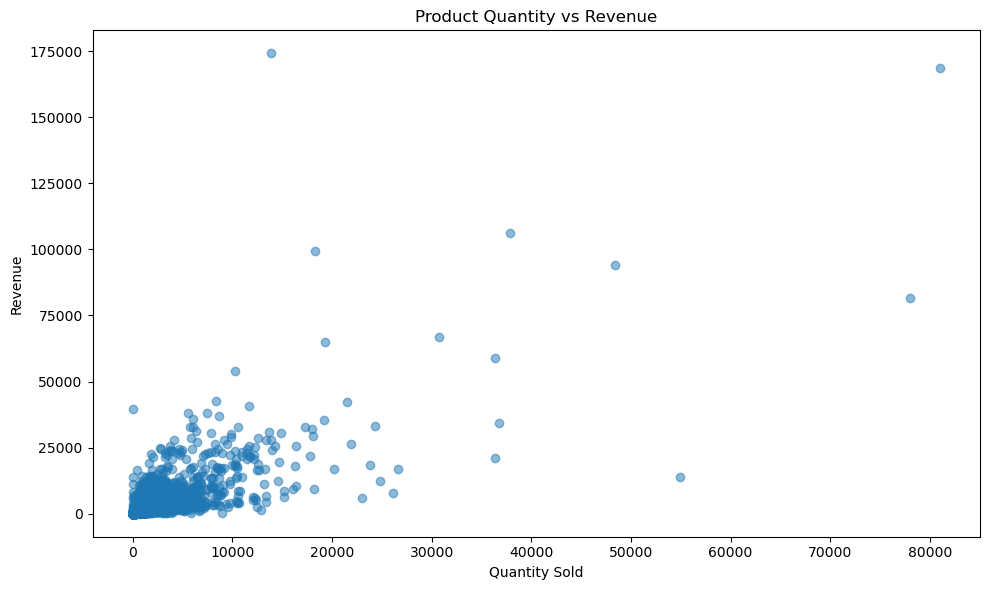

In [195]:
plt.figure(figsize=(10, 6))

plt.scatter(
    product_performance["Quantity"],
    product_performance["Revenue"],
    alpha=0.5
)

plt.title("Product Quantity vs Revenue")
plt.xlabel("Quantity Sold")
plt.ylabel("Revenue")

plt.tight_layout()
plt.show()

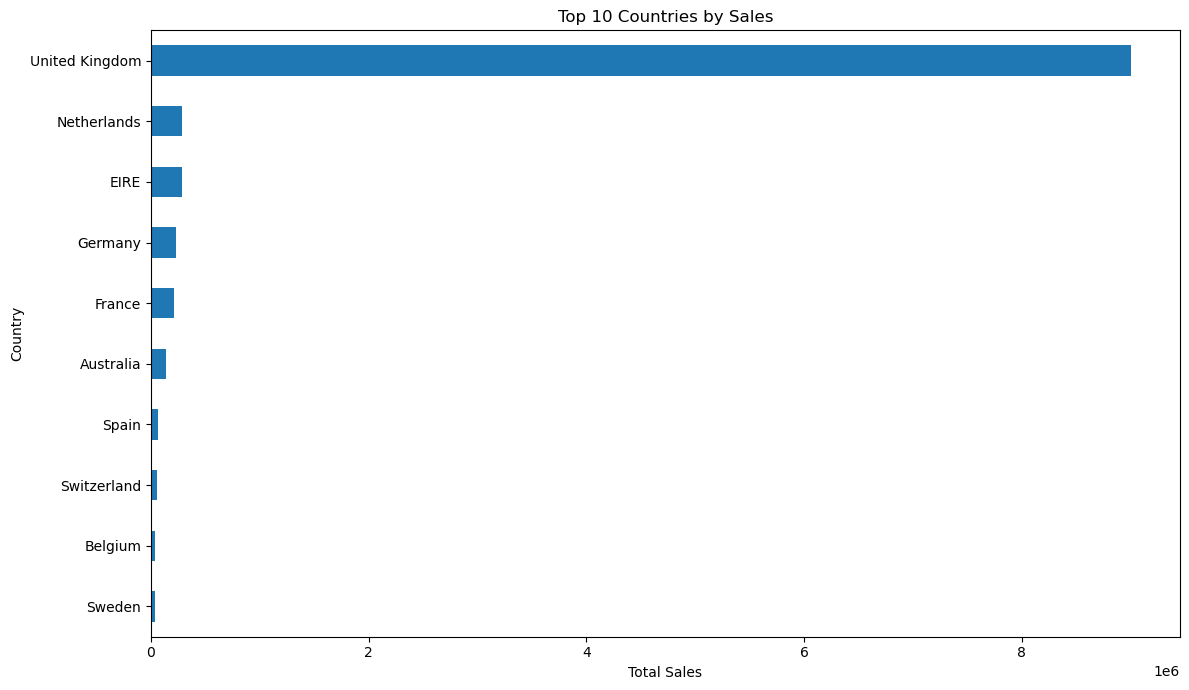

In [196]:
country_sales = (
    sales_df.groupby("Country")["TotalAmount"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)
plt.figure(figsize=(12, 7))
country_sales.sort_values().plot(kind="barh")
plt.title("Top 10 Countries by Sales")
plt.xlabel("Total Sales")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

In [197]:
print(product_sales["UnitPrice"].describe())

count    522729.000000
mean          3.335437
std          24.588654
min           0.001000
25%           1.250000
50%           2.080000
75%           4.130000
max       13541.330000
Name: UnitPrice, dtype: float64


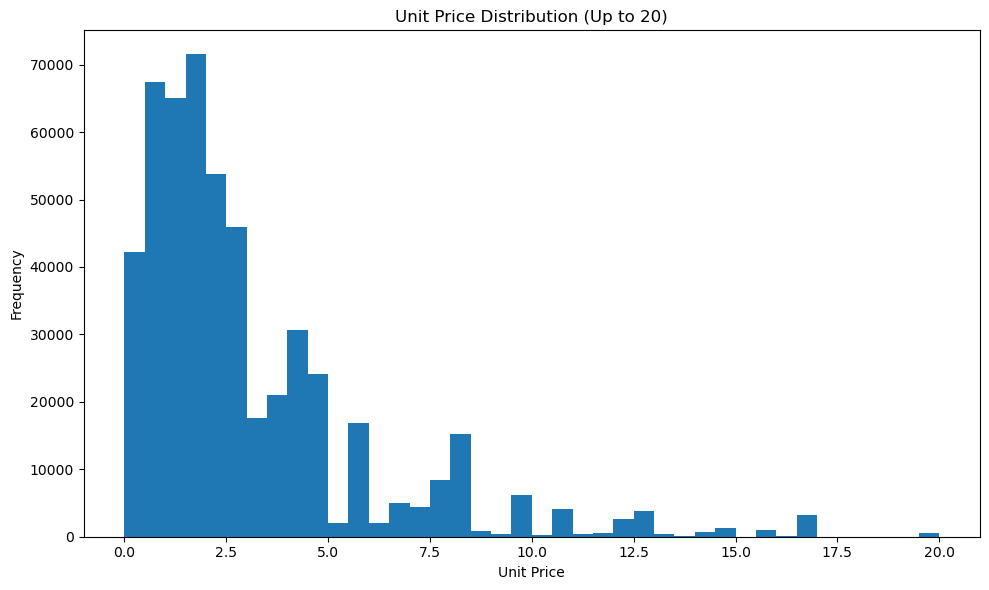

In [198]:
plt.figure(figsize=(10, 6))
plt.hist(
    product_sales.loc[product_sales["UnitPrice"] <= 20, "UnitPrice"],
    bins=40
)
plt.title("Unit Price Distribution (Up to 20)")
plt.xlabel("Unit Price")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

In [ ]:
## 9. Cancellation and Retention Analysis
      ====================================

In [199]:
cancelled_invoice_count = df.loc[
    df["InvoiceNo"].astype(str).str.startswith("C"),
    "InvoiceNo"
].nunique()

total_invoice_count = df["InvoiceNo"].nunique()

print("Cancelled invoices:", cancelled_invoice_count)
print("Total invoices:", total_invoice_count)

Cancelled invoices: 3836
Total invoices: 25900


In [200]:
cancellation_rate = (
    cancelled_invoice_count / total_invoice_count
) * 100

print("Cancellation Rate:", round(cancellation_rate, 2), "%")

Cancellation Rate: 14.81 %


In [201]:
cancelled_quantity = df.loc[
    df["InvoiceNo"].astype(str).str.startswith("C"),
    "Quantity"
].abs().sum()

print("Cancelled/Returned Quantity:", cancelled_quantity)

Cancelled/Returned Quantity: 275560


In [202]:
cancelled_value = df.loc[
    df["InvoiceNo"].astype(str).str.startswith("C"),
    "Quantity"
].abs() * df.loc[
    df["InvoiceNo"].astype(str).str.startswith("C"),
    "UnitPrice"
]

print("Cancelled Sales Value:", cancelled_value.sum())

Cancelled Sales Value: 893979.73


In [203]:
total_customers = rfm["CustomerID"].nunique()

repeat_customers = (
    rfm["Frequency"] > 1
).sum()

one_time_customers = (
    rfm["Frequency"] == 1
).sum()

print("Total Customers:", total_customers)
print("Repeat Customers:", repeat_customers)
print("One-time Customers:", one_time_customers)

Total Customers: 4338
Repeat Customers: 2845
One-time Customers: 1493


In [204]:
repeat_customer_rate = (
    repeat_customers / total_customers
) * 100

print("Repeat Customer Rate:", round(repeat_customer_rate, 2), "%")

Repeat Customer Rate: 65.58 %


In [ ]:
## 10. Key Business Insights
       =====================

In [205]:
print("Total Revenue:", round(sales_df["TotalAmount"].sum(), 2))
print("Total Orders:", sales_df["InvoiceNo"].nunique())
print("Total Customers:", rfm["CustomerID"].nunique())
print("Total Products:", product_sales["Description"].nunique())
print("Total Countries:", product_sales["Country"].nunique())

Total Revenue: 10642110.8
Total Orders: 19960
Total Customers: 4338
Total Products: 4023
Total Countries: 38


In [206]:
overall_aov = sales_df["TotalAmount"].sum() / sales_df["InvoiceNo"].nunique()

print("Overall Average Order Value:", round(overall_aov, 2))

Overall Average Order Value: 533.17


In [207]:
highest_sales_month = monthly_sales.idxmax()
highest_sales_value = monthly_sales.max()

print("Highest Sales Month:", highest_sales_month)
print("Highest Monthly Sales:",highest_sales_value)

Highest Sales Month: 2011-11-30 00:00:00
Highest Monthly Sales: 1503866.78


In [208]:
highest_revenue_product = top_revenue_products.idxmax()
highest_revenue_value = top_revenue_products.max()

print("Highest Revenue Product:", highest_revenue_product)
print("Revenue:", round(highest_revenue_value, 2))

Highest Revenue Product: REGENCY CAKESTAND 3 TIER
Revenue: 174156.54


In [209]:
highest_revenue_country = country_sales.idxmax()
highest_country_value = country_sales.max()

print("Highest Revenue Country:", highest_revenue_country)
print("Revenue:", round(highest_country_value, 2))

Highest Revenue Country: United Kingdom
Revenue: 9001744.09


In [ ]:
### Key Findings Summary

- The business generated approximately 10.64 million in revenue from 19,960 orders.
- November 2011 recorded the highest monthly sales, with approximately £1.16 million in revenue.
- The United Kingdom generated the highest country-level revenue, contributing approximately 8.75
   million.
- REGENCY CAKESTAND 3 TIER was the highest-revenue product, generating approximately 174,156.54.
- The analysis identified 4,338 customers, with a repeat customer rate of 65.58%.
- Champions were the highest-value customer segment, generating approximately 5.79 million in revenue.
- The analysis identified a significant number of Lost and At Risk customers, highlighting
  opportunities for customer re-engagement.
- Approximately 14.81% of unique invoices were cancelled, indicating that cancellation behaviour is
  an important area for business monitoring.

In [ ]:
## 11. Business Recommendations
       ========================

### 11.1 Retain High-Value Customers
- Focus on Champions with loyalty programs, exclusive offers, and personalized recommendations.
- Encourage high-value customers to continue purchasing through targeted engagement.

### 11.2 Re-engage At Risk Customers
- Identify At Risk customers and send targeted offers or reminders.
- Use their previous purchasing behaviour to create relevant promotions.

### 11.3 Win Back Lost Customers
- Create win-back campaigns for Lost Customers.
- Offer selected discounts or product recommendations based on previous purchases.

### 11.4 Convert New Customers into Repeat Customers
- Provide follow-up offers after the first purchase.
- Encourage New Customers to make their second purchase through personalized promotions.

### 11.5 Improve Cancellation Monitoring
- Monitor cancelled invoices and cancellation patterns.
- Investigate frequently cancelled products or orders to identify possible operational or
  customer-experience issues.

### 11.6 Focus on High-Performing Products
- Maintain availability of high-revenue products such as REGENCY CAKESTAND 3 TIER.
- Analyze top-selling products to identify opportunities for cross-selling and product bundles.

### 11.7 Monitor Market Concentration
- The United Kingdom contributes a large share of total revenue.
- Continue serving the UK market while also identifying opportunities to develop sales in other
  countries.

### 11.8 Use Customer Segmentation for Marketing
- Use RFM segments to create targeted marketing campaigns instead of treating all customers equally.
- Allocate different strategies to Champions, Loyal Customers, Potential Loyalists, New Customers,
  At Risk customers, and Lost Customers.

In [ ]:
## 12. Final Conclusion
       ================

This project analyzed retail transaction data to understand sales performance, customer behaviour,
product performance, market contribution, cancellations, and customer retention.

The analysis used Python, Pandas, NumPy, Matplotlib, and Seaborn for data cleaning, analysis,
visualization, and exploratory data analysis. RFM analysis was used to evaluate customer Recency, 
Frequency, and Monetary value, followed by customer segmentation.

The analysis identified important business patterns, including high-value customer segments,
repeat customer behaviour, top-performing products, major revenue-generating markets, monthly sales
trends, and cancellation patterns.

Overall, the project demonstrates how transaction-level data can be transformed into meaningful 
business insights and used to support customer retention, targeted marketing, product planning, 
and business decision-making.